In [80]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
import numpy as np
%matplotlib inline
#gerekli kütüphaneler

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


In [9]:
df = pd.read_csv('bedtime_screentime_sleep_debt.csv')
#Veri dosyası okundu

In [11]:
print("Veri Seti Boyutu:", df.shape)
print(df.info())
#Veri hakkında bazı bilgiler

Veri Seti Boyutu: (8500, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non

In [ ]:
#EDA

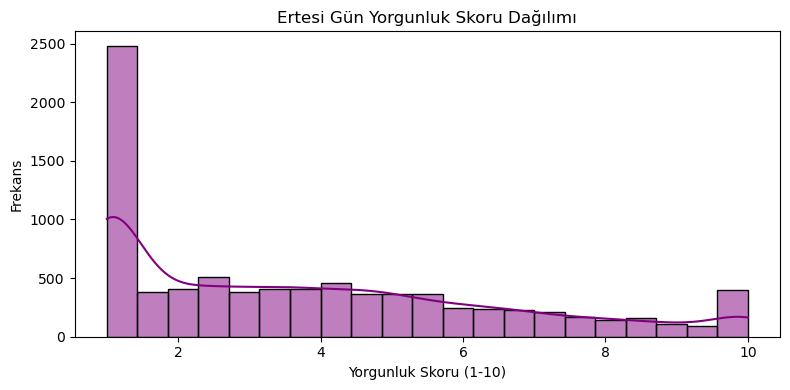

In [90]:
#Hedef Değişken dağılımı

plt.figure(figsize=(8, 4))
sns.histplot(df['next_day_fatigue_score'], kde=True, color='purple')
plt.title('Ertesi Gün Yorgunluk Skoru Dağılımı')
plt.xlabel('Yorgunluk Skoru (1-10)')
plt.ylabel('Frekans')
plt.tight_layout()
plt.show()

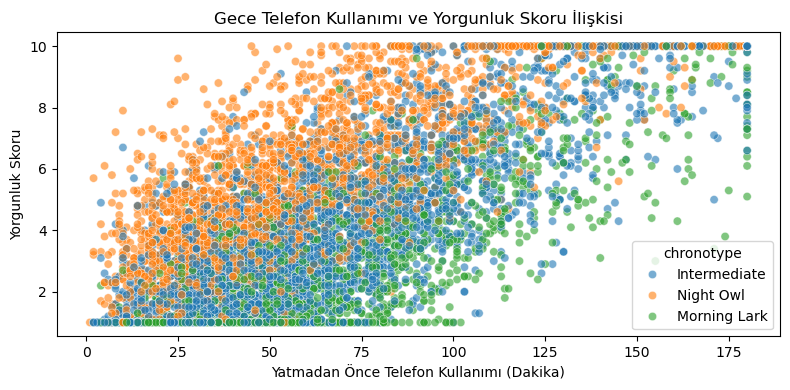

In [19]:
#Ekran Süresei ile yorgunluk Skrou ilişkisi
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='bedtime_phone_minutes', y='next_day_fatigue_score', hue='chronotype', alpha=0.6)
plt.title('Gece Telefon Kullanımı ve Yorgunluk Skoru İlişkisi')
plt.xlabel('Yatmadan Önce Telefon Kullanımı (Dakika)')
plt.ylabel('Yorgunluk Skoru')
plt.tight_layout()
plt.show()

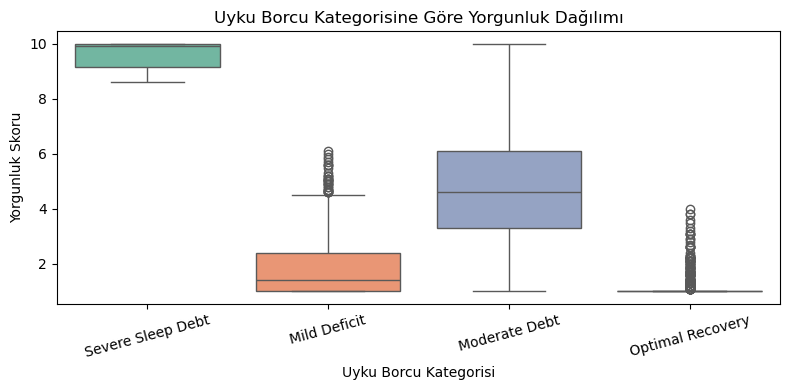

In [27]:
#Uyku süresi ile Yorgunluk dağılımı boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='sleep_debt_category', y='next_day_fatigue_score',hue='sleep_debt_category',legend=False,palette='Set2')
plt.title('Uyku Borcu Kategorisine Göre Yorgunluk Dağılımı')
plt.xlabel('Uyku Borcu Kategorisi')
plt.ylabel('Yorgunluk Skoru')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [35]:
features = [
    'age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes',
    'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active',
    'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min',
    'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes'
]
numeric_features = [
    'age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active',
    'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min',
    'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes'
]
categorical_features = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']

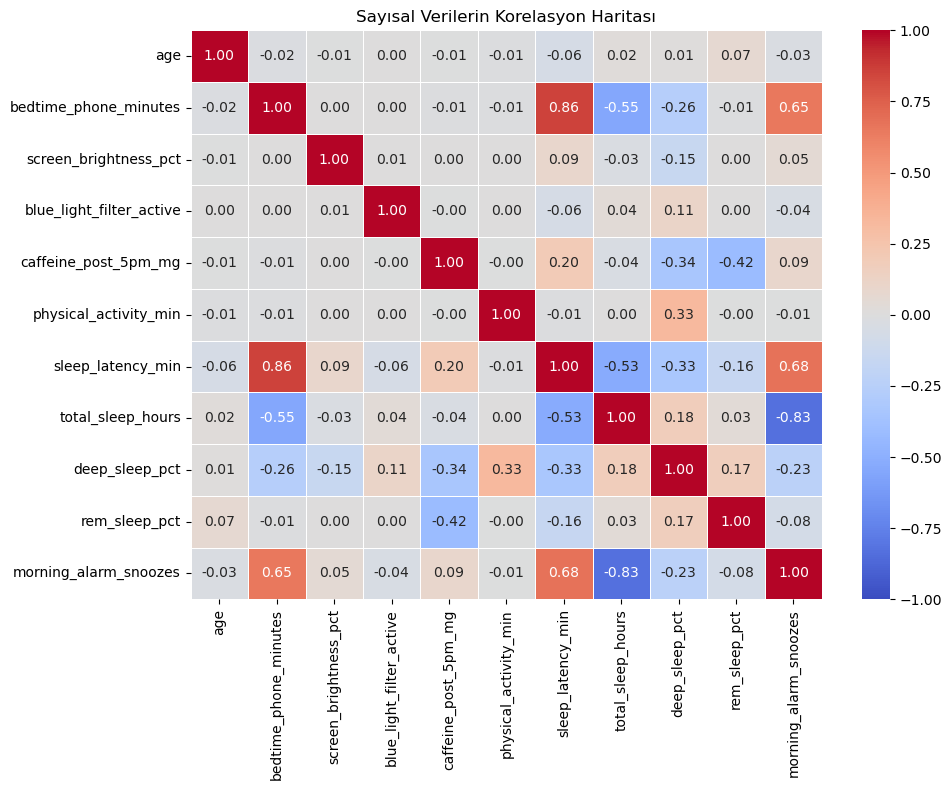

In [88]:
#Korelasyon
corr_matrix=df[numeric_features].corr()
#Isı haritsaı
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Sayısal Verilerin Korelasyon Haritası")
plt.tight_layout()
plt.show()

In [37]:
#Veri ön işleme
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [31]:
#Hedef belirleme
X = df[features]
y = df['next_day_fatigue_score']

In [41]:
#test ve train veri ayrımı
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) #%70 eğitim %30 test
print(f"\nEğitim Seti = {X_train.shape}, Test Seti = {X_test.shape}")


Eğitim Seti = (5950, 15), Test Seti = (2550, 15)


In [71]:
#Model1 Regresyon (Lineer Regresyon)

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

In [73]:
#Model2 Random Forest Regresyon

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)


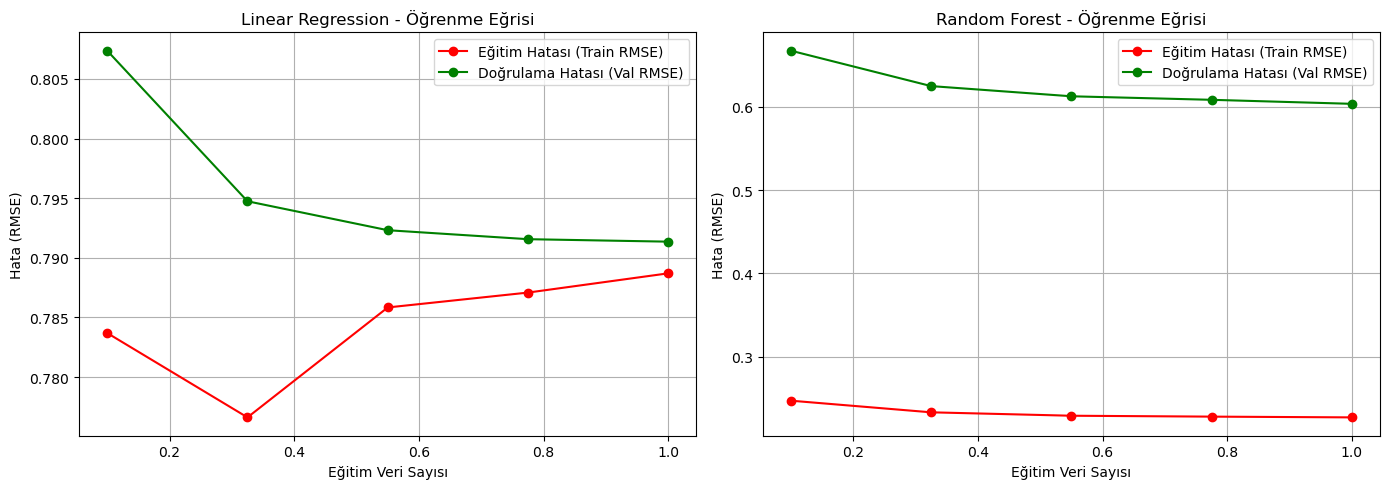

In [78]:
# Learning Curve hesaplama

train_sizes = np.linspace(0.1, 1.0, 5)

# 1. Linear Regression Eğrisi
_, train_scores_lr, test_scores_lr = learning_curve(
    lr_pipeline, X, y, cv=5, scoring='neg_mean_squared_error',
    train_sizes=train_sizes, n_jobs=-1
)
train_rmse_lr = np.sqrt(-train_scores_lr.mean(axis=1))
test_rmse_lr = np.sqrt(-test_scores_lr.mean(axis=1))

# 2. Random Forest Eğrisi
_, train_scores_rf, test_scores_rf = learning_curve(
    rf_pipeline, X, y, cv=5, scoring='neg_mean_squared_error',
    train_sizes=train_sizes, n_jobs=-1
)
train_rmse_rf = np.sqrt(-train_scores_rf.mean(axis=1))
test_rmse_rf = np.sqrt(-test_scores_rf.mean(axis=1))

# Yan Yana Grafik Çizimi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear Regression
axes[0].plot(train_sizes, train_rmse_lr, 'o-', color="r", label="Eğitim Hatası (Train RMSE)")
axes[0].plot(train_sizes, test_rmse_lr, 'o-', color="g", label="Doğrulama Hatası (Val RMSE)")
axes[0].set_title("Linear Regression - Öğrenme Eğrisi")
axes[0].set_xlabel("Eğitim Veri Sayısı")
axes[0].set_ylabel("Hata (RMSE)")
axes[0].legend(loc="best")
axes[0].grid(True)

# Random Forest
axes[1].plot(train_sizes, train_rmse_rf, 'o-', color="r", label="Eğitim Hatası (Train RMSE)")
axes[1].plot(train_sizes, test_rmse_rf, 'o-', color="g", label="Doğrulama Hatası (Val RMSE)")
axes[1].set_title("Random Forest - Öğrenme Eğrisi")
axes[1].set_xlabel("Eğitim Veri Sayısı")
axes[1].set_ylabel("Hata (RMSE)")
axes[1].legend(loc="best")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [49]:
#Model değerlendirme
def metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

mae_lr, rmse_lr, r2_lr = metrics(y_test, y_pred_lr)
mae_rf, rmse_rf, r2_rf = metrics(y_test, y_pred_rf)

print("\n================ MODEL PERFORMANS KARŞILAŞTIRMASI ================")
print(f"Linear Regression -> MAE: {mae_lr:.4f} | RMSE: {rmse_lr:.4f} | R²: {r2_lr:.4f}")
print(f"Random Forest     -> MAE: {mae_rf:.4f} | RMSE: {rmse_rf:.4f} | R²: {r2_rf:.4f}")


================ MODEL PERFORMANS KARŞILAŞTIRMASI ================
Linear Regression -> MAE: 0.6279 | RMSE: 0.7906 | R²: 0.9141
Random Forest     -> MAE: 0.4296 | RMSE: 0.6003 | R²: 0.9505


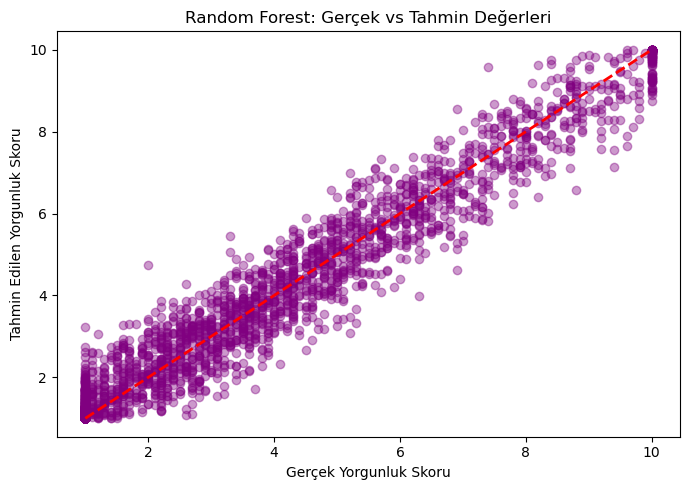

In [65]:
#Gerçek vs Tahmin Değerleri
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.4, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Random Forest: Gerçek vs Tahmin Değerleri')
plt.xlabel('Gerçek Yorgunluk Skoru')
plt.ylabel('Tahmin Edilen Yorgunluk Skoru')
plt.tight_layout()
plt.show()